In [275]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

Project Objectives: This dataset contains marks and performance of students, we will inestigate relationships of all students alomg with every.

In [276]:
import pyodbc                            #importing mysql to this 
print(pyodbc.drivers())

['SQL Server', 'ODBC Driver 17 for SQL Server', 'ODBC Driver 18 for SQL Server', 'Microsoft Access Driver (*.mdb, *.accdb)', 'Microsoft Excel Driver (*.xls, *.xlsx, *.xlsm, *.xlsb)', 'Microsoft Access Text Driver (*.txt, *.csv)', 'Microsoft Access dBASE Driver (*.dbf, *.ndx, *.mdx)']


In [277]:
# connecting to ssms for mysql server
from sqlalchemy import create_engine
from sqlalchemy.engine import URL
import pandas as pd

connection_url = URL.create(
    "mssql+pyodbc",
    query={
        "odbc_connect": (
            "DRIVER={ODBC Driver 18 for SQL Server};"
            r"SERVER=desktop-di3od2h\SQLEXPRESS01;"
            "DATABASE=campusx;"
            "Trusted_Connection=yes;"
            "Encrypt=yes;"
            "TrustServerCertificate=yes;"
        )
    }
)

connection = create_engine(connection_url)

print("SQLAlchemy engine created successfully!")

SQLAlchemy engine created successfully!


In [278]:
# data import directly from ssms as data is  present in ssms at campusx database
query = """
SELECT *
FROM dbo.StudentsPerformance;
"""
df = pd.read_sql_query(query, connection)
df.head()

,gender,race_ethnicity,parental_level_of_education,lunch,test_preparation_course,math_score,reading_score,writing_score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93
3,male,group A,associate's degree,free/reduced,none,47,57,44
4,male,group C,some college,standard,none,76,78,75


In [279]:

print("Dataset shape:", df.shape)
print("\nColumn names:", df.columns.tolist())

Dataset shape: (1000, 8)

Column names: ['gender', 'race_ethnicity', 'parental_level_of_education', 'lunch', 'test_preparation_course', 'math_score', 'reading_score', 'writing_score']


using mysql to know more about data as we are exploring the data

In [280]:
query = """                            -- count total records
SELECT count(*) as total_students 
from dbo.StudentsPerformance;
"""
pd.read_sql_query(query,connection)

,total_students
0,1000


In [281]:
query = """                    --check out column name and data types of column
select 
    column_name,
    data_type
from information_schema.columns
where table_name = 'StudentsPerformance'
order by ordinal_position
"""
pd.read_sql_query(query,connection)

,column_name,data_type
0,gender,nvarchar
1,race_ethnicity,nvarchar
2,parental_level_of_education,nvarchar
3,lunch,nvarchar
4,test_preparation_course,nvarchar
5,math_score,tinyint
6,reading_score,tinyint
7,writing_score,tinyint


In [282]:
# shortcut way to check missing values in data, if value is missing, add up
query = pd.read_sql_query('select * from dbo.StudentsPerformance;', connection)
query.isnull().sum()
# query = """
# select *
# from dbo.query = StudentsPerformance;
# """


gender                         0
race_ethnicity                 0
parental_level_of_education    0
lunch                          0
test_preparation_course        0
math_score                     0
reading_score                  0
writing_score                  0
dtype: int64

In [283]:
# it also checks missing value column by column, if it's found sum it up by 1
query = """
SELECT
    SUM(CASE WHEN gender IS NULL THEN 1 ELSE 0 END) AS missing_gender,
    SUM(CASE WHEN race_ethnicity IS NULL THEN 1 ELSE 0 END) AS missing_race,
    SUM(CASE WHEN parental_level_of_education IS NULL
             THEN 1 ELSE 0 END) AS missing_parent_education,
    SUM(CASE WHEN lunch IS NULL THEN 1 ELSE 0 END) AS missing_lunch,
    SUM(CASE WHEN test_preparation_course IS NULL
             THEN 1 ELSE 0 END) AS missing_test_prep,
    SUM(CASE WHEN math_score IS NULL THEN 1 ELSE 0 END) AS missing_math,
    SUM(CASE WHEN reading_score IS NULL THEN 1 ELSE 0 END) AS missing_reading,
    SUM(CASE WHEN writing_score IS NULL THEN 1 ELSE 0 END) AS missing_writing
FROM dbo.StudentsPerformance;
"""

pd.read_sql_query(query, connection)

,missing_gender,missing_race,missing_parent_education,missing_lunch,missing_test_prep,missing_math,missing_reading,missing_writing
0,0,0,0,0,0,0,0,0


There's no missing value in data

In [284]:
query = """               
select
    avg(cast(math_score as float)) as average_math,
    avg(cast(reading_score as float)) as average_reading,
    avg(cast(writing_score as float)) as average_score,
    min(math_score) as lowest_math,
    max(math_score) as highest_math
from dbo.StudentsPerformance;
"""
pd.read_sql_query(query, connection)

,average_math,average_reading,average_score,lowest_math,highest_math
0,66.089,69.169,68.054,0,100


now pandas, so first we load data to pandas and numpy

In [285]:
# already we load data in df
print("Rows and columns:", df.shape)
display(df.head)

Rows and columns: (1000, 8)


<bound method NDFrame.head of      gender race_ethnicity parental_level_of_education         lunch  \
0    female        group B           bachelor's degree      standard   
1    female        group C                some college      standard   
2    female        group B             master's degree      standard   
3      male        group A          associate's degree  free/reduced   
4      male        group C                some college      standard   
..      ...            ...                         ...           ...   
995  female        group E             master's degree      standard   
996    male        group C                 high school  free/reduced   
997  female        group C                 high school  free/reduced   
998  female        group D                some college      standard   
999  female        group D                some college  free/reduced   

    test_preparation_course  math_score  reading_score  writing_score  
0                      none      

In [286]:
print("Dataset dimensions:", df.shape)    #inspecting dataset

print(type(df))

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

Dataset dimensions: (1000, 8)
<class 'pandas.DataFrame'>

Column names:
['gender', 'race_ethnicity', 'parental_level_of_education', 'lunch', 'test_preparation_course', 'math_score', 'reading_score', 'writing_score']

Data types:
gender                           str
race_ethnicity                   str
parental_level_of_education      str
lunch                            str
test_preparation_course          str
math_score                     int64
reading_score                  int64
writing_score                  int64
dtype: object

Missing values:
gender                         0
race_ethnicity                 0
parental_level_of_education    0
lunch                          0
test_preparation_course        0
math_score                     0
reading_score                  0
writing_score                  0
dtype: int64

Duplicate rows: 0


In [287]:
df.describe()             #gives numeric calculation for every numeric columns

,math_score,reading_score,writing_score
count,1000.00000,1000.000000,1000.000000
mean,66.08900,69.169000,68.054000
std,15.16308,14.600192,15.195657
min,0.00000,17.000000,10.000000
25%,57.00000,59.000000,57.750000
50%,66.00000,70.000000,69.000000
75%,77.00000,79.000000,79.000000
max,100.00000,100.000000,100.000000


In [288]:
math_scores = df["math_score"].to_numpy()      #using numpy to check that pandas is correct or not
print("Mean:", np.mean(math_scores))
print("Median:", np.median(math_scores))
print("Standard deviation:", np.std(math_scores))
print("Minimum:", np.min(math_scores))
print("Maximum:", np.max(math_scores))

Mean: 66.089
Median: 66.0
Standard deviation: 15.155496659628149
Minimum: 0
Maximum: 100


EDA

In [289]:
# which subject has highest average score?
score_columns = [
    "math_score",
    "reading_score",
    "writing_score"
]
average_scores = df[score_columns].mean()
print(average_scores)

math_score       66.089
reading_score    69.169
writing_score    68.054
dtype: float64


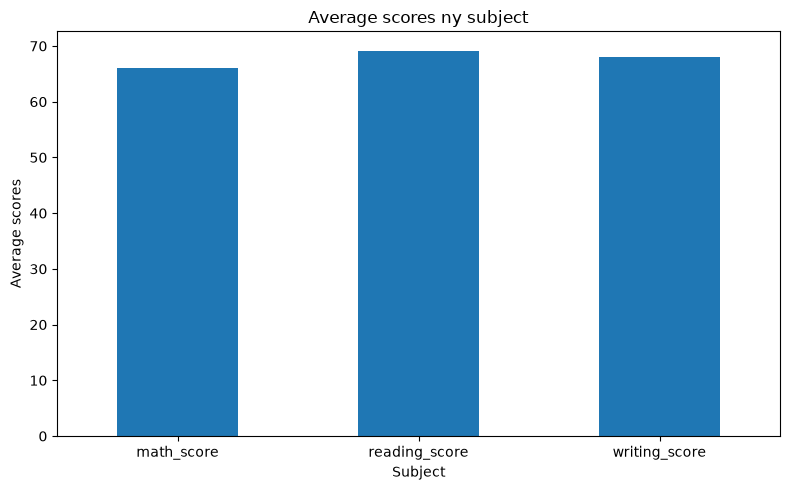

In [290]:
average_scores.plot(kind="bar", figsize=(8,5))       #plotting marks
plt.title("Average scores ny subject")
plt.xlabel("Subject")
plt.ylabel("Average scores")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

2) How math scores are distributed.
to solve it:,
think are most students clustered around middle of score range,
are there usually high or low scores
does distribution is symmetric or screwed
For all this, histogram shiws the shape of distribution

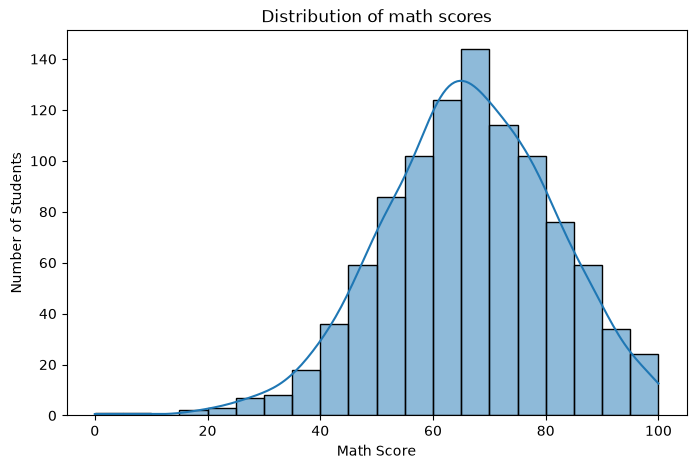

In [291]:
plt.figure(figsize=(8,5))
sns.histplot(data=df,x="math_score",bins=20,kde=True)
plt.title("Distribution of math scores")
plt.xlabel("Math Score")
plt.ylabel("Number of Students")
plt.show()

3) Are math, reading, writing scores are related 

In [292]:
correlation = df[score_columns].corr()
print(correlation)

               math_score  reading_score  writing_score
math_score       1.000000       0.817580       0.802642
reading_score    0.817580       1.000000       0.954598
writing_score    0.802642       0.954598       1.000000


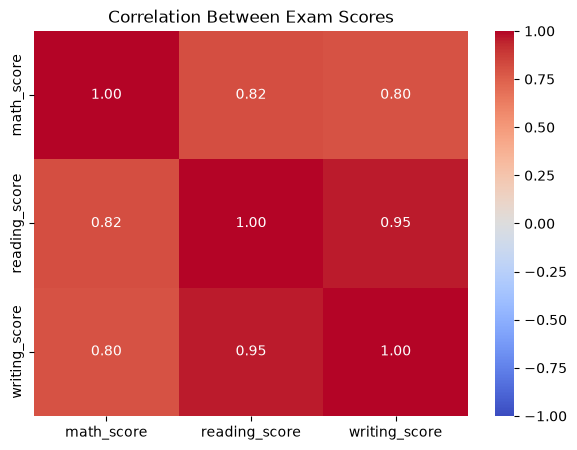

In [293]:
plt.figure(figsize=(7, 5))

sns.heatmap(
    data= correlation,
    annot=True,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    fmt=".2f"
)

plt.title("Correlation Between Exam Scores")
plt.show()

investigate the factor associated with performance

4) does test preparation related to higher scores

In [294]:
query = """
SELECT
    test_preparation_course,
    COUNT(*) AS student_count,
    AVG(CAST(math_score AS FLOAT)) AS avg_math,
    AVG(CAST(reading_score AS FLOAT)) AS avg_reading,
    AVG(CAST(writing_score AS FLOAT)) AS avg_writing
FROM dbo.StudentsPerformance
GROUP BY test_preparation_course
ORDER BY test_preparation_course;
"""

prep_analysis = pd.read_sql_query(query, connection)
display(prep_analysis)

,test_preparation_course,student_count,avg_math,avg_reading,avg_writing
0,completed,358,69.695531,73.893855,74.418994
1,none,642,64.077882,66.534268,64.504673


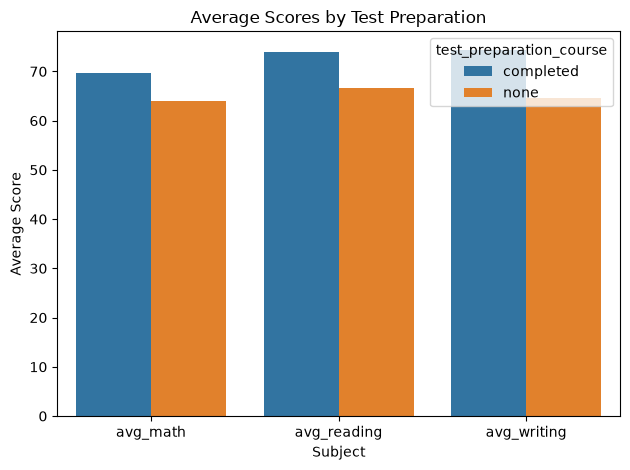

In [295]:
prep_plot = prep_analysis.melt(            # visulaizing
    id_vars="test_preparation_course",
    value_vars=["avg_math", "avg_reading", "avg_writing"],
    var_name="subject",
    value_name="average_score"
)
# prep_plot
sns.barplot(
    data=prep_plot,
    x="subject",
    y="average_score",
    hue="test_preparation_course"
)

plt.title("Average Scores by Test Preparation")
plt.xlabel("Subject")
plt.ylabel("Average Score")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

How do scores differ by gender

In [296]:
gender_analysis = df.groupby("gender")[score_columns].mean()
display(gender_analysis)

,math_score,reading_score,writing_score
gender,,,
female,63.633205,72.608108,72.467181
male,68.728216,65.473029,63.311203


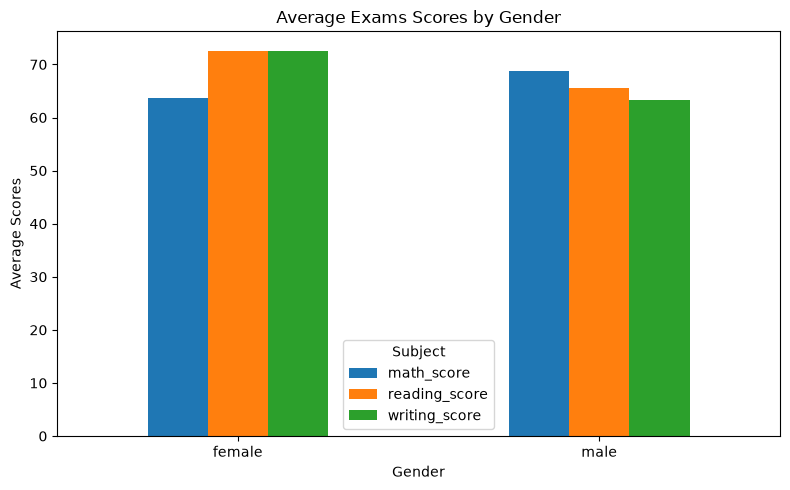

In [297]:
gender_analysis.plot(
    kind='bar',
    figsize=(8,5)
)
plt.title("Average Exams Scores by Gender")
plt.xlabel('Gender')
plt.ylabel('Average Scores')
plt.xticks(rotation=0)
plt.legend(title="Subject")
plt.tight_layout()
plt.show()


is parental education associated with scores

In [298]:
parent_analysis = (
    df.groupby("parental_level_of_education")[score_columns]
      .mean()
      .sort_values("math_score")
)

display(parent_analysis)

,math_score,reading_score,writing_score
parental_level_of_education,,,
high school,62.137755,64.704082,62.448980
some high school,63.497207,66.938547,64.888268
some college,67.128319,69.460177,68.840708
associate's degree,67.882883,70.927928,69.896396
bachelor's degree,69.389831,73.000000,73.381356
master's degree,69.745763,75.372881,75.677966


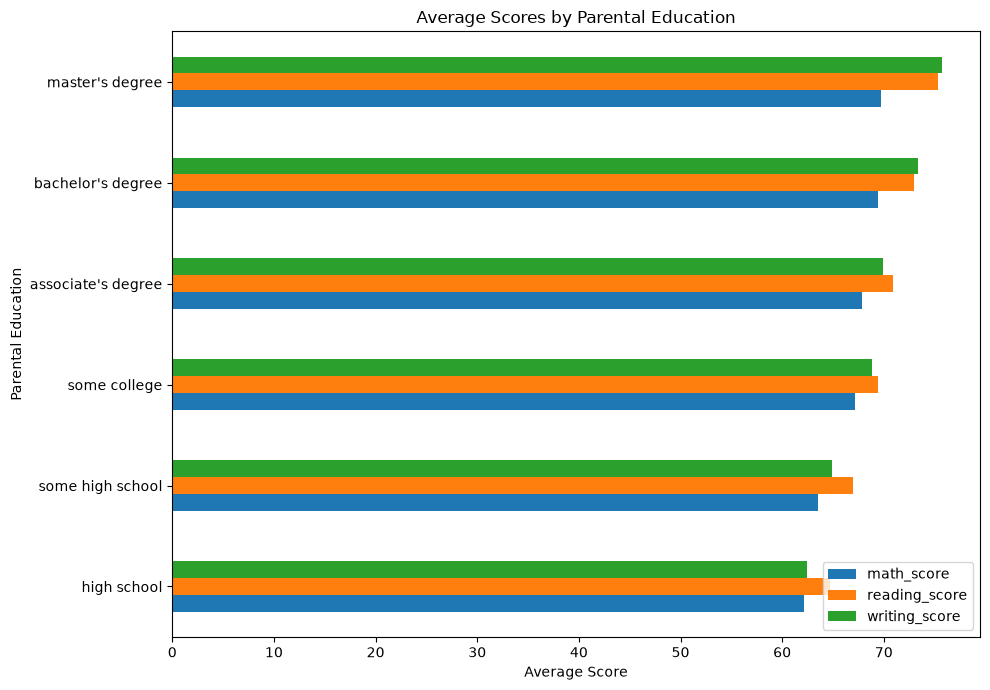

In [299]:
parent_analysis.plot(
    kind="barh",
    figsize=(10, 7)
)

plt.title("Average Scores by Parental Education")
plt.xlabel("Average Score")
plt.ylabel("Parental Education")
plt.tight_layout()
plt.show()

is lunch type associated with scores

In [300]:
lunch_analysis = (
    df.groupby("lunch")[score_columns]
      .mean()
)

display(lunch_analysis)

,math_score,reading_score,writing_score
lunch,,,
free/reduced,58.921127,64.653521,63.022535
standard,70.034109,71.654264,70.823256


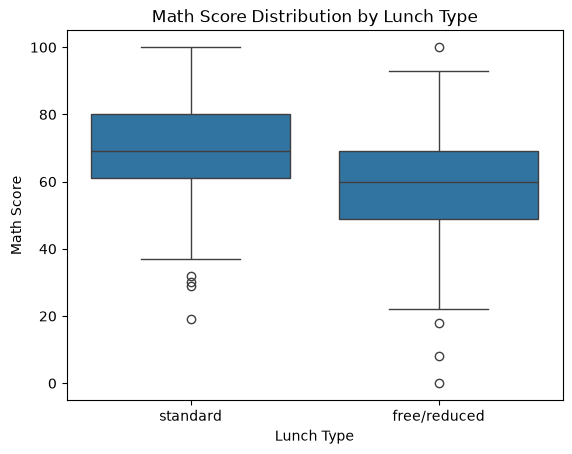

In [301]:
sns.boxplot(
    data=df,
    x="lunch",
    y="math_score"
)

plt.title("Math Score Distribution by Lunch Type")
plt.xlabel("Lunch Type")
plt.ylabel("Math Score")
plt.show()

How do scores vary across race/ethnicity groups?

In [302]:
race_analysis = (
    df.groupby("race_ethnicity")[score_columns]
      .agg(["mean", "median", "count"])
)

display(race_analysis)

math_score              reading_score               \
                     mean median count          mean median count   
race_ethnicity                                                      
group A         61.629213   61.0    89     64.674157   64.0    89   
group B         63.452632   63.0   190     67.352632   67.0   190   
group C         64.463950   65.0   319     69.103448   71.0   319   
group D         67.362595   69.0   262     70.030534   71.0   262   
group E         73.821429   74.5   140     73.028571   74.0   140   

               writing_score               
                        mean median count  
race_ethnicity                             
group A            62.674157   62.0    89  
group B            65.600000   67.0   190  
group C            67.827586   68.0   319  
group D            70.145038   72.0   262  
group E            71.407143   72.0   140

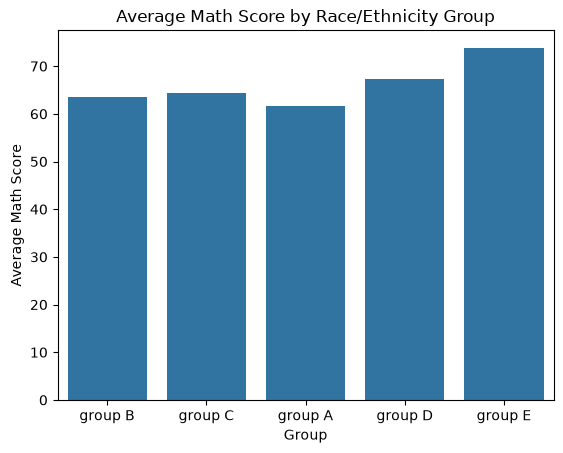

In [303]:
sns.barplot(
    data=df,
    x="race_ethnicity",
    y="math_score",
    errorbar=None
)

plt.title("Average Math Score by Race/Ethnicity Group")
plt.xlabel("Group")
plt.ylabel("Average Math Score")
plt.show()

phase 5: deeper anylsis


In [304]:
score_columns

['math_score', 'reading_score', 'writing_score']

In [305]:
df["average_score"] = df[score_columns].mean(axis=1)   #adding a new column of average score
df[[
    "math_score",
    "reading_score",
    "writing_score",
    "average_score"
]].head()

,math_score,reading_score,writing_score,average_score
0,72,72,74,72.666667
1,69,90,88,82.333333
2,90,95,93,92.666667
3,47,57,44,49.333333
4,76,78,75,76.333333


In [306]:
#Find the ten students with the highest average across the three recorded subjects:
top_students = df.nlargest(10, "average_score")
display(top_students)

,gender,race_ethnicity,parental_level_of_education,lunch,test_preparation_course,math_score,reading_score,writing_score,average_score
458,female,group E,bachelor's degree,standard,none,100,100,100,100.000000
916,male,group E,bachelor's degree,standard,completed,100,100,100,100.000000
962,female,group E,associate's degree,standard,none,100,100,100,100.000000
114,female,group E,bachelor's degree,standard,completed,99,100,100,99.666667
179,female,group D,some high school,standard,completed,97,100,100,99.000000
712,female,group D,some college,standard,none,98,100,99,99.000000
165,female,group C,bachelor's degree,standard,completed,96,100,100,98.666667
625,male,group D,some college,standard,completed,100,97,99,98.666667
149,male,group E,associate's degree,free/reduced,completed,100,100,93,97.666667
685,female,group E,master's degree,standard,completed,94,99,100,97.666667


In [307]:
#how many students scored 90 or above in maths?
#in sql
query = """              
select
count(*) as  students_scoring_90_or_above
from dbo.StudentsPerformance
where math_score >= 90;
"""
pd.read_sql_query(query, connection)

,students_scoring_90_or_above
0,58


In [308]:
#in pandas
high_math = df[df["math_score"] >= 90]

print("Students scoring 90 or above:", len(high_math))
display(high_math.head())

Students scoring 90 or above: 58


,gender,race_ethnicity,parental_level_of_education,lunch,test_preparation_course,math_score,reading_score,writing_score,average_score
2,female,group B,master's degree,standard,none,90,95,93,92.666667
34,male,group E,some college,standard,none,97,87,82,88.666667
104,male,group C,some college,standard,completed,98,86,90,91.333333
114,female,group E,bachelor's degree,standard,completed,99,100,100,99.666667
121,male,group B,associate's degree,standard,completed,91,89,92,90.666667


In [309]:
#How many students scored below 40 in each subject?
# in sql
query = """
SELECT
    SUM(CASE WHEN math_score < 40 THEN 1 ELSE 0 END) AS low_math,
    SUM(CASE WHEN reading_score < 40 THEN 1 ELSE 0 END) AS low_reading,
    SUM(CASE WHEN writing_score < 40 THEN 1 ELSE 0 END) AS low_writing
FROM dbo.StudentsPerformance;
"""

pd.read_sql_query(query, connection)

,low_math,low_reading,low_writing
0,40,26,32


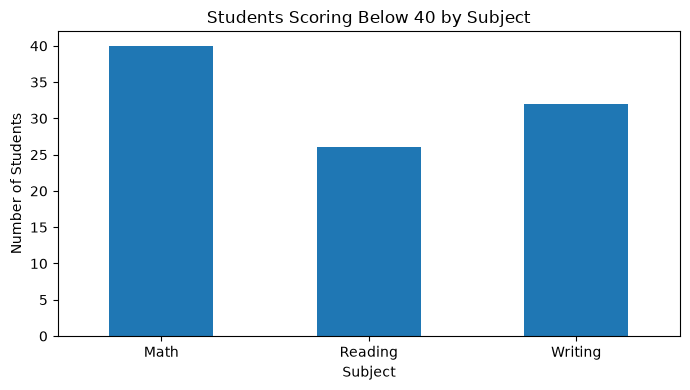

In [310]:
#by pandas
low_counts = (df[[
    "math_score",
    "reading_score",
    "writing_score"
]] < 40).sum()
low_counts.index = ["Math", "Reading", "Writing"]
low_counts

# by matplotlib to vusualize
low_counts.plot(kind="bar", figsize=(7, 4))

plt.title("Students Scoring Below 40 by Subject")
plt.xlabel("Subject")
plt.ylabel("Number of Students")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

Calculate each student's average score using NumPy

In [311]:
scores = df[score_columns].to_numpy()     # first converting pandas to  numpy
scores
df["average_score"] = np.mean(scores, axis=1)      #axis=1 calculates the average across the three subjects for each row.

display(
    df[score_columns + ["average_score"]].head()
)

,math_score,reading_score,writing_score,average_score
0,72,72,74,72.666667
1,69,90,88,82.333333
2,90,95,93,92.666667
3,47,57,44,49.333333
4,76,78,75,76.333333


In [312]:
print("Overall average:", round(np.mean(scores), 2))
print("Median of all subject scores:", round(np.median(scores), 2))
print("Highest subject score:", np.max(scores))
print("Lowest subject score:", np.min(scores))

Overall average: 67.77
Median of all subject scores: 68.0
Highest subject score: 100
Lowest subject score: 0


Which students have the highest average scores?
We don't have student names or IDs in the columns shown, so we'll identify the highest-scoring records by their row position in the DataFrame.

In [313]:

df["record_number"] = np.arange(1, len(df) + 1)
df
top_students = (
    df.nlargest(10, "average_score")
      [["record_number"] + score_columns + ["average_score"]]
)

display(top_students)

,record_number,math_score,reading_score,writing_score,average_score
458,459,100,100,100,100.000000
916,917,100,100,100,100.000000
962,963,100,100,100,100.000000
114,115,99,100,100,99.666667
179,180,97,100,100,99.000000
712,713,98,100,99,99.000000
165,166,96,100,100,98.666667
625,626,100,97,99,98.666667
149,150,100,100,93,97.666667
685,686,94,99,100,97.666667


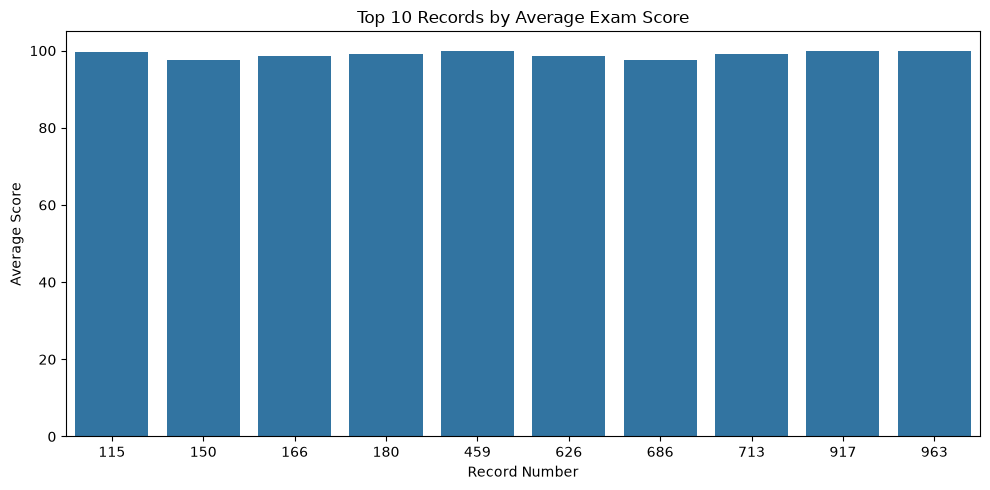

In [314]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=top_students,
    x="record_number",
    y="average_score"
)

plt.title("Top 10 Records by Average Exam Score")
plt.xlabel("Record Number")
plt.ylabel("Average Score")
plt.tight_layout()
plt.show()

Which subject is each student's strongest?
The idxmax() method in pandas returns the index label of the first occurrence of the maximum value along a specified axis.

In [315]:
df["best_subject"] = (
    df[score_columns]
    .idxmax(axis=1)
    .str.replace("_score", "", regex=False)
    .str.title()
)

display(df[score_columns + ["best_subject"]].head())

,math_score,reading_score,writing_score,best_subject
0,72,72,74,Writing
1,69,90,88,Reading
2,90,95,93,Reading
3,47,57,44,Reading
4,76,78,75,Reading


best_subject
Reading    400
Math       354
Writing    246
Name: count, dtype: int64


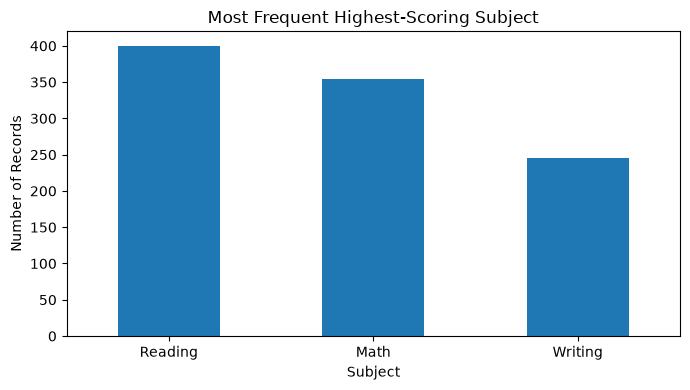

In [316]:
best_subject_counts = df["best_subject"].value_counts()

print(best_subject_counts)

best_subject_counts.plot(
    kind="bar",
    figsize=(7, 4)
)

plt.title("Most Frequent Highest-Scoring Subject")
plt.xlabel("Subject")
plt.ylabel("Number of Records")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

Compare performance across two categories
Let's investigate whether average math scores differ by both gender and test preparation status.

In [317]:
query = """
SELECT
    gender,
    test_preparation_course,
    COUNT(*) AS student_count,
    AVG(CAST(math_score AS FLOAT)) AS avg_math,
    AVG(CAST(reading_score AS FLOAT)) AS avg_reading,
    AVG(CAST(writing_score AS FLOAT)) AS avg_writing
FROM dbo.StudentsPerformance
GROUP BY gender, test_preparation_course
ORDER BY gender, test_preparation_course;
"""

group_analysis = pd.read_sql_query(query, connection)
group_analysis

,gender,test_preparation_course,student_count,avg_math,avg_reading,avg_writing
0,female,completed,184,67.195652,77.375000,78.793478
1,female,none,334,61.670659,69.982036,68.982036
2,male,completed,174,72.339080,70.212644,69.793103
3,male,none,308,66.688312,62.795455,59.649351


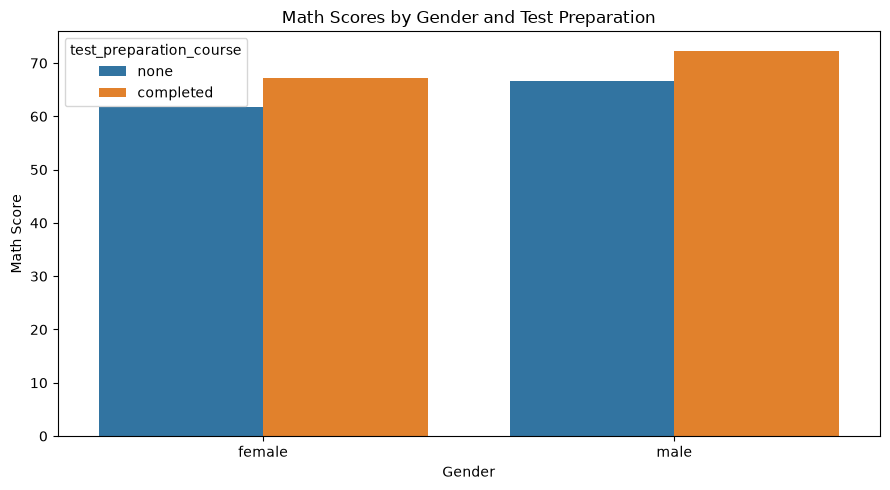

In [318]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=df,
    x="gender",
    y="math_score",
    hue="test_preparation_course",
    errorbar=None
)

plt.title("Math Scores by Gender and Test Preparation")
plt.xlabel("Gender")
plt.ylabel("Math Score")
plt.tight_layout()
plt.show()

Compare mean and median scores
The mean can be affected by unusually high or low values. The median gives the middle score when values are sorted.

In [319]:
comparison = df[score_columns].agg(["mean", "median"]).T

comparison.columns = ["Mean", "Median"]

display(comparison)

,Mean,Median
math_score,66.089,66.0
reading_score,69.169,70.0
writing_score,68.054,69.0


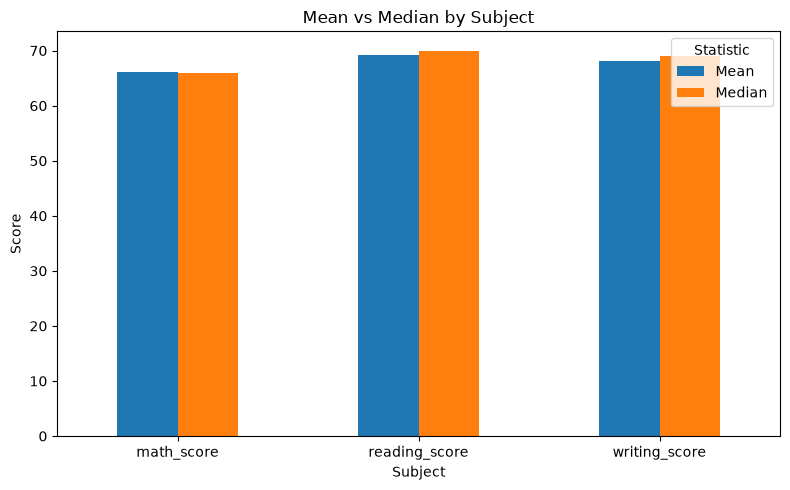

In [320]:
comparison.plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Mean vs Median by Subject")
plt.xlabel("Subject")
plt.ylabel("Score")
plt.xticks(rotation=0)
plt.legend(title="Statistic")
plt.tight_layout()
plt.show()

Detect potential outliers using the IQR method
The interquartile range (IQR) measures the spread of the middle 50% of scores.
The usual lower and upper fences are:
Lower fence=Q_1-1.5(IQR)
text{Upper fence}=Q_3+1.5(IQR)

In [321]:
outlier_summary = []

for column in score_columns:
    q1 = df[column].quantile(0.25)
    q3 = df[column].quantile(0.75)
    iqr = q3 - q1

    lower_fence = q1 - 1.5 * iqr
    upper_fence = q3 + 1.5 * iqr

    outliers = df[
        (df[column] < lower_fence) |
        (df[column] > upper_fence)
    ]

    outlier_summary.append({
        "subject": column,
        "Q1": q1,
        "Q3": q3,
        "IQR": iqr,
        "lower_fence": lower_fence,
        "upper_fence": upper_fence,
        "outlier_count": len(outliers)
    })

outlier_summary = pd.DataFrame(outlier_summary)

display(outlier_summary)

,subject,Q1,Q3,IQR,lower_fence,upper_fence,outlier_count
0,math_score,57.00,77.0,20.00,27.000,107.000,8
1,reading_score,59.00,79.0,20.00,29.000,109.000,6
2,writing_score,57.75,79.0,21.25,25.875,110.875,5


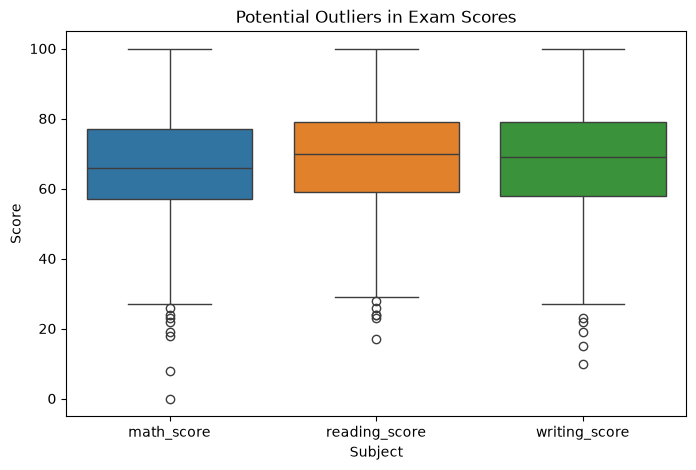

In [322]:
plt.figure(figsize=(8, 5))

sns.boxplot(data=df[score_columns])

plt.title("Potential Outliers in Exam Scores")
plt.xlabel("Subject")
plt.ylabel("Score")
plt.show()

Bonus: Compare SQL results with pandas results
A useful portfolio habit is checking whether two approaches give the same answer.

In [323]:
sql_average = pd.read_sql_query("""
SELECT
    AVG(CAST(math_score AS FLOAT)) AS avg_math,
    AVG(CAST(reading_score AS FLOAT)) AS avg_reading,
    AVG(CAST(writing_score AS FLOAT)) AS avg_writing
FROM dbo.StudentsPerformance;
""", connection)

pandas_average = df[score_columns].mean()

print("SQL averages:")
display(sql_average)

print("Pandas averages:")
display(pandas_average)

SQL averages:


,avg_math,avg_reading,avg_writing
0,66.089,69.169,68.054


Pandas averages:


math_score       66.089
reading_score    69.169
writing_score    68.054
dtype: float64

In [324]:
%pip install sqlalchemy pyodbc

#used to download sql alchemy

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip
